# 1. Data Extraction

Utilized Selenium to download multi-year airline market data (2022–2025) from the TranStats BTS website. The notebook automatically obtains a compatible Microsoft Edge WebDriver; Microsoft Edge must be installed to run the data-extraction section.

In [1]:
from IPython.display import display, HTML
display(HTML("<style>.container{width:95% !important;}</style>"))

### 1.1 User Input

In [2]:
import os
from pathlib import Path

# Keep downloaded and generated data local to the repository.
T100_DIR = Path('data') / 't100'
T100_DIR.mkdir(parents=True, exist_ok=True)

# Select the desired timeframe for downloading
YEARS_TO_DOWNLOAD = ['2022', '2023', '2024', '2025']

### 1.2 Library check

In [3]:
import subprocess
import sys

# The name of the package to check and install
PACKAGE_NAME = 'selenium'

try:
    # 1. Check if the library is installed by attempting to import it
    import selenium
    print(f"{PACKAGE_NAME} is already installed. Version: {selenium.__version__}")

except ImportError:
    print(f"{PACKAGE_NAME} is NOT installed. Attempting to install...")
    
    # 2. If import fails, use subprocess to run the pip install command
    try:
        # We use 'sys.executable' to ensure we are using the pip associated 
        # with the currently running Python environment (important for virtual environments)
        subprocess.check_call([sys.executable, "-m", "pip", "install", PACKAGE_NAME])
        
        # 3. After successful installation, try to import again
        import selenium
        print(f"Successfully installed and imported {PACKAGE_NAME}.")
        
    except subprocess.CalledProcessError as e:
        print(f"ERROR: Failed to install {PACKAGE_NAME}. Please check your internet connection or permissions.")
        print(f"Details: {e}")
    except Exception as e:
        print(f"An unexpected error occurred: {e}")

selenium is already installed. Version: 4.35.0


In [ ]:
import time
from selenium import webdriver
from selenium.webdriver.edge.options import Options
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.support.ui import Select

import glob
from zipfile import ZipFile

import pandas as pd
pd.set_option('display.max_columns', None)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.dates import DateFormatter
import seaborn as sns
import math

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import warnings
warnings.filterwarnings('ignore')

### 1.3 Load Web Driver

In [5]:
# Configure Edge Options for Automatic Download ---
edge_options = Options()

prefs = {
    "download.prompt_for_download": False, # Important: disables the save file dialog
    "download.directory_upgrade": True,
    "safebrowsing.enabled": True # Optional, improves security/stability
}

# The 'prefs' are added as an experimental option
edge_options.add_experimental_option("prefs", prefs)
# Optional: for stability in some environments
edge_options.add_argument("--no-sandbox")
edge_options.add_argument("--disable-dev-shm-usage")

# Optional: run in headless mode (no browser window)
edge_options.add_argument("--headless")


def setup_driver():
    return webdriver.Edge(options=edge_options)
    

def set_download_path_via_command(driver, download_path):
    # Sends a direct command to the WebDriver to force the download location.
    driver.execute_cdp_cmd(
        "Page.setDownloadBehavior",
        {
            "behavior": "allow", 
            "downloadPath": download_path,
            "eventsEnabled": True
        }
    )

### 1.4 Setup data

In [6]:
# URL for the data download page
T100_URL = 'https://www.transtats.bts.gov/DL_SelectFields.aspx?gnoyr_VQ=FIL&QO_fu146_anzr='

    
def download_t100_csv(driver, url, years):
    """Navigates the site and initiates the CSV download."""

    # --- Setup Driver and Download path ---
    set_download_path_via_command(driver, os.path.abspath(T100_DIR))

    driver.get(url)
    print(f"\nNavigating to: {url}")
    wait = WebDriverWait(driver, 30)

    # 1. Wait for a key element on the page
    year_dropdown_id = 'cboYear' 
    # Wait until the element is present
    wait.until(EC.presence_of_element_located((By.ID, year_dropdown_id)))
    print("Page loaded. \nSelecting Year...")

    # 2. Select All Fields/Columns
    print("Selecting all Fields/Columns...")
    wait.until(EC.element_to_be_clickable((By.ID, 'chkAllVars'))).click()

    
    time.sleep(5)
    

    # 3. Selecting a year
    year_select = Select(driver.find_element(By.ID, year_dropdown_id))

    for year in years:
        
        start = time.time()
        
        try:
            year_select.select_by_value(year)

            # 4. Click the final 'Download' button
            print(f"\nDownloading T100 data for {year}")
            wait.until(EC.element_to_be_clickable((By.ID, 'btnDownload'))).click()

            # --- IMPORTANT STEP: Wait for the download to complete ---
            time.sleep(120)
            timeout = 120 # Increase timeout as TranStats files can be large
            end_time = time.time() + timeout

            downloaded_file = None
            while time.time() < end_time:
                # Look for any file that is not a temporary Edge download file
                files = [f for f in os.listdir(T100_DIR) if not f.endswith(('.crdownload', '.tmp'))]
                if files:
                    downloaded_file = files[0]
                    break
                time.sleep(1)
            
            end = time.time()
            elapsed_time = end - start

            if downloaded_file:
                print(f"{downloaded_file} downloaded successfully in {elapsed_time:.0f} seconds.")
            else:
                print(f"\nDownload timed out or failed - session time is {elapsed_time:.0f} seconds. Check manually in the directory if download is successful.")

        except Exception as e:
            print(f"\nAn error occurred for {year}: {e}")
            print(f"session time is {elapsed_time:.0f} seconds")
            continue

### 1.5 Download data

In [ ]:
if __name__ == '__main__':
    
    driver = setup_driver()
    
    print(f"\nDownload directory set to: {T100_DIR}")
    download_t100_csv(driver, T100_URL, YEARS_TO_DOWNLOAD)

### 1.6 Append CSV files

In [ ]:
zip_files = glob.glob(str(T100_DIR / '*.zip'))

# Check if any zip files were found
if not zip_files:
    print("No .zip files found in the current directory.")
else:
    # Create an empty list to store individual DataFrames
    df_all = []

    # Loop through each zip file found
    for zip_file_path in zip_files:
        print(f"Processing: {zip_file_path}")
        
        # Use ZipFile to open the archive
        with ZipFile(zip_file_path) as z:
            # Get a list of all files inside the zip
            file_list = z.namelist()
            
            # Find the first CSV file in the archive (assuming only one per zip)
            csv_file_in_zip = next((f for f in file_list if f.endswith('.csv')), None)
            
            if csv_file_in_zip:
                # Read the CSV directly from the zip file object using z.open()
                df = pd.read_csv(z.open(csv_file_in_zip))
                df_all.append(df)
            else:
                print(f"Warning: No CSV file found in {zip_file_path}. Skipping.")

    # Combine all DataFrames into a single one
    if df_all:
        df_t100 = pd.concat(df_all, ignore_index=True)
        print("\nSuccessfully combined all CSVs from zip files.")
        
        df_t100.to_csv(T100_DIR / 'data_t100.csv', index=False)
        print(f"\ndata_t100.csv is the combined dataset downloaded to: {T100_DIR}")
    else:
        print("\nNo dataframes were loaded.")

### 1.7 Check combined dataset

In [9]:
df_t100.head()

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,AIRLINE_ID,UNIQUE_CARRIER_NAME,UNIQUE_CARRIER_ENTITY,REGION,CARRIER,CARRIER_NAME,CARRIER_GROUP,CARRIER_GROUP_NEW,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,YEAR,QUARTER,MONTH,DISTANCE_GROUP,CLASS
0,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10185,1018502,30185,AEX,"Alexandria, LA",LA,22,Louisiana,72,10185,1018502,30185,AEX,"Alexandria, LA",LA,22,Louisiana,72,2022,1,3,1,L
1,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10466,1046602,30466,AZA,"Phoenix, AZ",AZ,4,Arizona,81,10466,1046602,30466,AZA,"Phoenix, AZ",AZ,4,Arizona,81,2022,1,1,1,L
2,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10590,1059006,30590,IFP,"Bullhead City, AZ",AZ,4,Arizona,81,10590,1059006,30590,IFP,"Bullhead City, AZ",AZ,4,Arizona,81,2022,1,1,1,L
3,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10590,1059006,30590,IFP,"Bullhead City, AZ",AZ,4,Arizona,81,10590,1059006,30590,IFP,"Bullhead City, AZ",AZ,4,Arizona,81,2022,1,2,1,L
4,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10781,1078105,30781,BTR,"Baton Rouge, LA",LA,22,Louisiana,72,10781,1078105,30781,BTR,"Baton Rouge, LA",LA,22,Louisiana,72,2022,1,3,1,L


#  

-----------------------------------------------------------------------------------------------------------------------------------------------

# 2. Preprocessing, EDA & Feature Engineering

## 2.1 Load Dataset

In [5]:
df_raw = pd.read_csv(T100_DIR / 'data_t100.csv')

df_raw.head()

,PASSENGERS,FREIGHT,MAIL,DISTANCE,UNIQUE_CARRIER,AIRLINE_ID,UNIQUE_CARRIER_NAME,UNIQUE_CARRIER_ENTITY,REGION,CARRIER,CARRIER_NAME,CARRIER_GROUP,CARRIER_GROUP_NEW,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_ABR,ORIGIN_STATE_FIPS,ORIGIN_STATE_NM,ORIGIN_WAC,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,DEST_CITY_NAME,DEST_STATE_ABR,DEST_STATE_FIPS,DEST_STATE_NM,DEST_WAC,YEAR,QUARTER,MONTH,DISTANCE_GROUP,CLASS
0,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10185,1018502,30185,AEX,"Alexandria, LA",LA,22,Louisiana,72,10185,1018502,30185,AEX,"Alexandria, LA",LA,22,Louisiana,72,2022,1,3,1,L
1,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10466,1046602,30466,AZA,"Phoenix, AZ",AZ,4,Arizona,81,10466,1046602,30466,AZA,"Phoenix, AZ",AZ,4,Arizona,81,2022,1,1,1,L
2,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10590,1059006,30590,IFP,"Bullhead City, AZ",AZ,4,Arizona,81,10590,1059006,30590,IFP,"Bullhead City, AZ",AZ,4,Arizona,81,2022,1,1,1,L
3,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10590,1059006,30590,IFP,"Bullhead City, AZ",AZ,4,Arizona,81,10590,1059006,30590,IFP,"Bullhead City, AZ",AZ,4,Arizona,81,2022,1,2,1,L
4,0.0,0.0,0.0,0.0,09Q,21161.0,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",01130,D,09Q,"Swift Air, LLC d/b/a Eastern Air Lines d/b/a E...",2,2.0,10781,1078105,30781,BTR,"Baton Rouge, LA",LA,22,Louisiana,72,10781,1078105,30781,BTR,"Baton Rouge, LA",LA,22,Louisiana,72,2022,1,3,1,L


## 2.2 Data Summary

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 898074 entries, 0 to 898073
Data columns (total 36 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   PASSENGERS             898074 non-null  float64
 1   FREIGHT                897869 non-null  float64
 2   MAIL                   898074 non-null  float64
 3   DISTANCE               898074 non-null  float64
 4   UNIQUE_CARRIER         898050 non-null  object 
 5   AIRLINE_ID             898050 non-null  float64
 6   UNIQUE_CARRIER_NAME    898050 non-null  object 
 7   UNIQUE_CARRIER_ENTITY  898050 non-null  object 
 8   REGION                 898050 non-null  object 
 9   CARRIER                898074 non-null  object 
 10  CARRIER_NAME           898050 non-null  object 
 11  CARRIER_GROUP          898074 non-null  int64  
 12  CARRIER_GROUP_NEW      898050 non-null  float64
 13  ORIGIN_AIRPORT_ID      898074 non-null  int64  
 14  ORIGIN_AIRPORT_SEQ_ID  898074 non-nu

### 2.2.1 Keep only important columns - exclude columns that are irrelavant and have redundant information**

In [7]:
col = ['PASSENGERS','DISTANCE','DISTANCE_GROUP','CARRIER_NAME',
       'ORIGIN_AIRPORT_ID','ORIGIN_CITY_NAME','ORIGIN_STATE_NM',
       'DEST_AIRPORT_ID','DEST_CITY_NAME','DEST_STATE_NM',
       'YEAR','QUARTER','MONTH'
      ]

df = df_raw[col]

df['DISTANCE_GROUP'] = df['DISTANCE_GROUP'].astype(str)
df['ORIGIN_AIRPORT_ID'] = df['ORIGIN_AIRPORT_ID'].astype(str)
df['DEST_AIRPORT_ID'] = df['DEST_AIRPORT_ID'].astype(str)

In [8]:
data_types = df.dtypes.astype(str)

df_summ = pd.concat({'DataType': data_types,
                     'Unique': df.nunique(),
                     'Count': df.count().round(1),
                     'Null': df.isnull().sum(),
                     'Zero': (df==0).sum(),
                     'Min': df.select_dtypes(include=[np.number]).min().round(1),
                     'Max': df.select_dtypes(include=[np.number]).max().round(1),
                     'Mean': df.select_dtypes(include=[np.number]).mean().round(1),
                     '25%': df.select_dtypes(include=[np.number]).quantile(0.25).round(1),
                     '75%': df.select_dtypes(include=[np.number]).quantile(0.75).round(1),
                     '-ve': (df.select_dtypes(include=[np.number])<0).sum(),          
                    }, axis=1)

df_summ.head(15)

,DataType,Unique,Count,Null,Zero,Min,Max,Mean,25%,75%,-ve
PASSENGERS,float64,37160,898074,0,155019,0.0,98536.0,3253.7,6.0,3732.0,0.0
DISTANCE,float64,3045,898074,0,4834,0.0,7948.0,809.5,298.0,1099.0,0.0
DISTANCE_GROUP,object,16,898074,0,0,NaN,NaN,NaN,NaN,NaN,NaN
CARRIER_NAME,object,119,898050,24,0,NaN,NaN,NaN,NaN,NaN,NaN
ORIGIN_AIRPORT_ID,object,1613,898074,0,0,NaN,NaN,NaN,NaN,NaN,NaN
ORIGIN_CITY_NAME,object,1442,898068,6,0,NaN,NaN,NaN,NaN,NaN,NaN
ORIGIN_STATE_NM,object,53,898074,0,0,NaN,NaN,NaN,NaN,NaN,NaN
DEST_AIRPORT_ID,object,1640,898074,0,0,NaN,NaN,NaN,NaN,NaN,NaN
DEST_CITY_NAME,object,1472,898068,6,0,NaN,NaN,NaN,NaN,NaN,NaN
DEST_STATE_NM,object,53,898074,0,0,NaN,NaN,NaN,NaN,NaN,NaN


- The data covers a period from **Jan 2022 to July 2025** indicating a multi-year time series.

- The **PASSENGERS** column has a high number of **zero entries (155,019)**, suggesting that over 150,000 records are **flights with no passengers**.

- The distribution of flight distances is skewed towards the short end, with the **average distance** being **809.5 miles** and 75% of flights being 1,099 miles or less.

- The primary metric columns (PASSENGERS, DISTANCE, YEAR, MONTH) have no missing values, and **CARRIER_NAME (24 nulls)** & **ORIGIN/DEST_CITY_NAME (6 nulls)** have **negligible missing data**.

- The mean DISTANCE_GROUP is 2.2, and the 75th percentile is 3.0, confirming that most flight segments fall within the shorter distance groups.



### 2.2.2 Data consistency check

In [9]:
# --- Checking for Inconsistent Numeric Data in 'object' Columns ---

# Select only object (string) columns
object_cols = df.select_dtypes(include=['object']).columns

# Initialize a dictionary to store the results
results = {}

for col in object_cols:
    
    # Attempt to coerce the entire column to numeric. 
    # If a value cannot be parsed as a number (e.g., 'abc'), it becomes NaN.
    coerced_series = pd.to_numeric(df[col], errors='coerce')
    
    # Identify values that successfully converted (they were numeric-like)
    is_numeric = coerced_series.notna()
    
    # Store the analysis results
    results[col] = {'Numeric-Like Count': is_numeric.sum()}

# Convert results dictionary to a DataFrame for clean output
consistency_check_df = pd.DataFrame(results).T

print("Data Consistency Check for Object Columns:")

# Rename columns and format percentage for clean display
consistency_check_df = consistency_check_df.rename(columns={
    'Numeric-Like Count': 'Count (Numeric/String-Number)',
})

consistency_check_df.head(10)

Data Consistency Check for Object Columns:


,Count (Numeric/String-Number)
DISTANCE_GROUP,898074
CARRIER_NAME,0
ORIGIN_AIRPORT_ID,898074
ORIGIN_CITY_NAME,0
ORIGIN_STATE_NM,0
DEST_AIRPORT_ID,898074
DEST_CITY_NAME,0
DEST_STATE_NM,0


- There are **no mixed data types** (where text strings and numeric-like strings are mingled) within the core object columns.

- The Distance group and airport ID columns (ORIGIN_AIRPORT_ID and DEST_AIRPORT_ID), are 100% numeric-like (898,074 counts), so **no data anamolies**.

- Remaining object colums are pure text/categorical fields.

In [10]:
# Dropping missing values as they are negligible (24)
df = df.dropna()

# Format datetime
df['DATE'] = pd.to_datetime(df['YEAR'].astype(str) + '-' + df['MONTH'].astype(str) + '-01')

-----------------------------------------------------------------------------------------------------------------------------------------------------------------


## 2.3 EDA: Trend Analysis

### 2.3.1 Monthly Passenger Demand Over Time

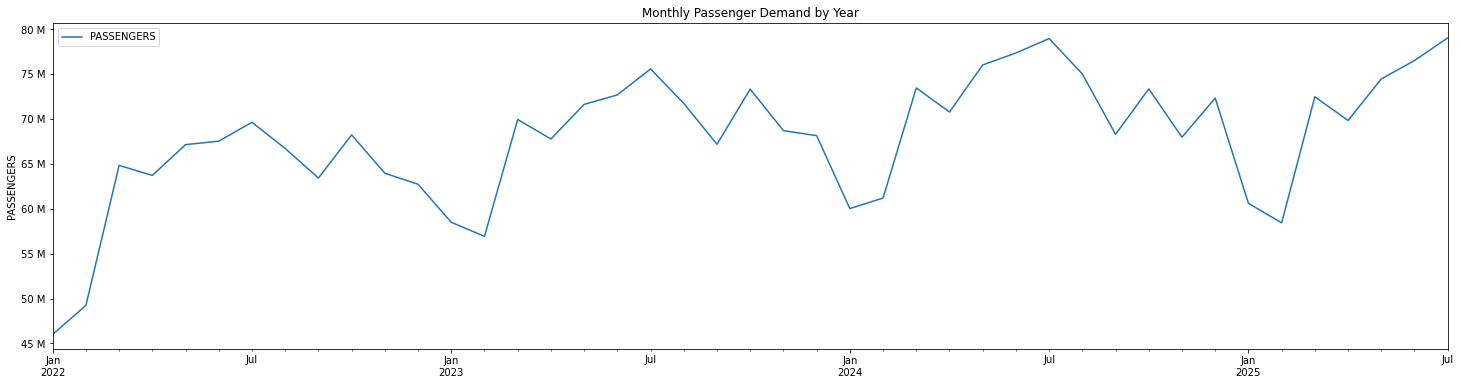

In [11]:
# Aggregate to monthly total passengers
df_monthly = df.groupby('DATE', as_index=False)['PASSENGERS'].sum()
df_monthly = df_monthly.set_index('DATE').asfreq('MS') # MS = month start


df_monthly.plot(figsize=(25,6), title="Monthly Passenger Demand by Year")

# Define a function to format the y-axis tick labels
def millions_formatter(x, pos):
    """The two args are the value and tick position."""
    # Divide by 1,000,000 and append 'M'
    return f'{x/1000000:.0f} M'

# Apply the custom formatter to the y-axis
formatter = ticker.FuncFormatter(millions_formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.xlabel('')
plt.ylabel('PASSENGERS')

plt.show()

- The data shows a **strong and consistent upward growth trend** in monthly passenger volume starting from 2022 to 2025 July.

- **Annual seasonal pattern** is observed, with passenger demand peaking each year in the summer months (July/August).

- The lowest points in passenger demand (the seasonal troughs) occur at the beginning of each year (Quarter 1), likely due to reduced winter travel.




### 2.3.2 Monthly Passengers by Year

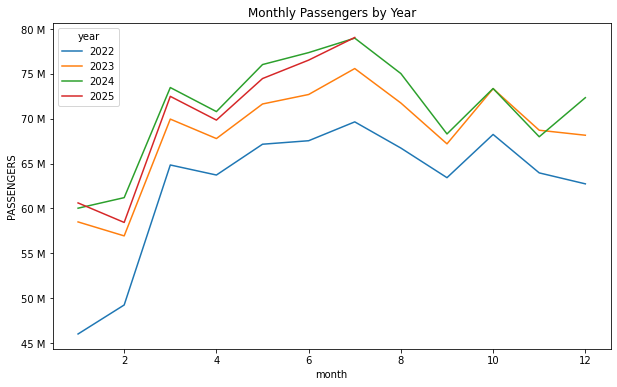

In [12]:
df_monthly['year'] = df_monthly.index.year
df_monthly['month'] = df_monthly.index.month

df_yearly = df_monthly.pivot(index='month', columns='year', values='PASSENGERS')

# Check if the amplitude grows over time
df_yearly.plot(figsize=(10,6), title="Monthly Passengers by Year")

# Define a function to format the y-axis tick labels
def millions_formatter(x, pos):
    """The two args are the value and tick position."""
    # Divide by 1,000,000 and append 'M'
    return f'{x/1000000:.0f} M'

# Apply the custom formatter to the y-axis
formatter = ticker.FuncFormatter(millions_formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.ylabel('PASSENGERS')

plt.show()

- July has the highest passengers traffic, followed by June & August, suggesting these months as the busiest months for air travel.

- January & February are months with the lowest passenger traffic, confirming lowest points in the annual demand.

- There is a significant drop in passenger volume every year from the peak in June-August to the shoulder season in September.

- Jan & Feb 2022 are the lowest points in the data, possibly becuase travel started picking up in early 2022 post covid.


### 2.3.3 Additive Decomposition

On visual inspection of the monthly trend plot - the magnitude of the seasonal flucutations (the size of peaks and troughs) are roughly constant over time suggesting Additive Decomposition is appropriate.

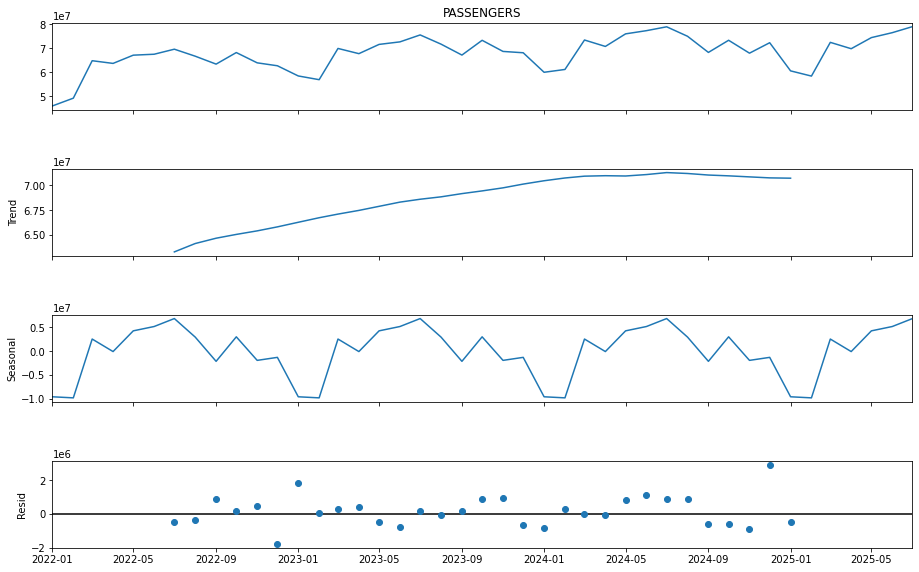

In [13]:
decomp = seasonal_decompose(df_monthly['PASSENGERS'], model='additive', period=12)
fig = decomp.plot()
fig.set_size_inches(14,9)
plt.show()

- The Trend component confirms the observation of a clear upward trajectory in total passenger volume over the years.

- The Seasonal component shows a repetitive pattern that cycles over 12 months, validating the annual seasonality.

- The Residuals show the points are scattered randomly and evenly around the horizontal line at 0, showing no clear pattern formation (which is the requirement).


### 2.3.4 ACF plot

Checking for direct and indirect correlations between the current observation and the lag values in the time series.

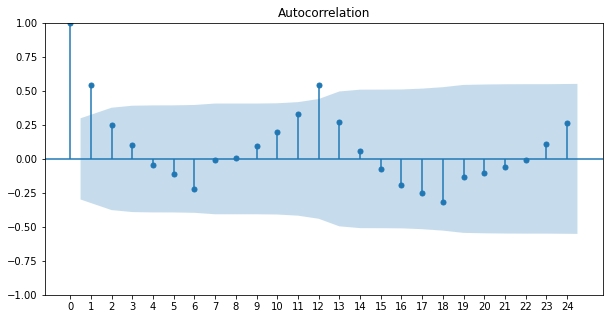

In [14]:
# with lags=24
fig, ax = plt.subplots(figsize=(10,5))

plot_acf(df_monthly['PASSENGERS'], lags=24, ax=ax)

ax.set_xticks(range(0, 25))  # from 0 to 24, every step

plt.show()

The ACF plot is crucial for identifying the order of the ARIMA or SARIMA model.


- The ACF decays slowly and sinusoidally, where the autocorrelation coefficients remain significant for many lags - a sign of non-stationary data (presence of a strong trend).

- Lag 1 is significant (outside the blue shaded area).

- Another significant spike is present at lag 12 indicating seasonality.


The slow decay to zero suggests that the data must be differenced at least once (or seasonally differenced) to achieve stationarity before applying an ARMA model.

### 2.3.5 Using correlation metrics to re-confirm if the above lags are highly correlated with the current observation

In [15]:
df_monthly['lag_1'] = df_monthly['PASSENGERS'].shift(1)
corr_lag1 = df_monthly['PASSENGERS'].corr(df_monthly['lag_1'])
print(f"Correlation at lag 1: {corr_lag1:.2f}")

df_monthly['lag_12'] = df_monthly['PASSENGERS'].shift(12)
corr_lag12 = df_monthly['PASSENGERS'].corr(df_monthly['lag_12'])
print(f"Correlation at lag 12: {corr_lag12:.2f}")

Correlation at lag 1: 0.64
Correlation at lag 12: 0.91


### 2.3.6 Augmented Dickey-Fuller (ADF) test for stationarity

In [16]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df_monthly['PASSENGERS'])
print(f"ADF Statistic: {result[0]:.2f}")
print(f"p-value: {result[1]:.2f}")

ADF Statistic: -2.09
p-value: 0.25


- The p-value of 0.25 is high (much greater than the standard $\alpha=0.05$ or $\alpha=0.10$), which leads to the failure to reject the null hypothesis and can conclude the series is likely non-stationary.

- The ADF test statistic is NOT sufficiently negative to conclude that the series is stationary at the standard significance levels, which supports the p-value result.


### 2.3.7 PCAF plot
PACF is plotted to check the "true" direct correlations between the current observation and the intermediate lags (which ACF plot does not speak about).

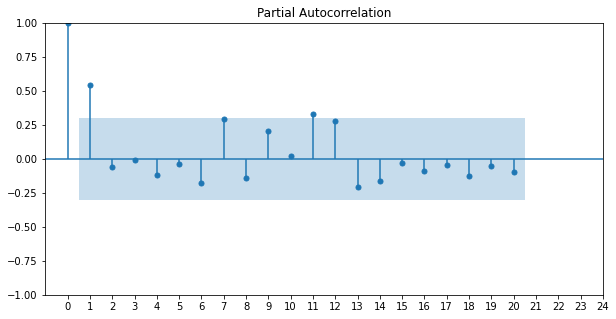

In [17]:
# with lags=24
fig, ax = plt.subplots(figsize=(10,5))

plot_pacf(df_monthly['PASSENGERS'], lags=20, ax=ax, method='ywm')  # method='ywm' is recommended

ax.set_xticks(range(0, 25))  # from 0 to 24, every step

plt.show()

- The plot shows an intial significant spike followed by a "cut-off" (after lag 1) indicating that there is no cascading effect of the intermediate lags on the current observation.

- Initial AR Component: The sharp cutoff after lag 1 suggests a potential non-seasonal autoregressive (AR) component of order $\mathbf{p=1}$ or $\mathbf{p=2}$ for a stationary series.

### 2.3.8 Checking strength of Seasonality and Trend

In [18]:
from statsmodels.tsa.seasonal import STL

stl = STL(df_monthly['PASSENGERS'], period=12).fit()
trend = stl.trend
seasonal = stl.seasonal
resid = stl.resid

trend_strength = 1 - (resid.var() / (trend + resid).var())
season_strength = 1 - (resid.var() / (seasonal + resid).var())

print("Trend Strength:", round(trend_strength, 3))
print("Seasonal Strength:", round(season_strength, 3))

Trend Strength: 0.967
Seasonal Strength: 0.987


**Trend Strength (0.967):**  Indicates a clear, persistent upward pattern in passenger counts over time.

**Seasonal Strength (0.987):**  Recurring, periodic effects are exceptionally strong.

Both trend and seasonality are dominant features, so seasonal models (SARIMA, Fourier features, seasonal regressions) are more important than trend-only models.  Forecasting models that ignore either trend or seasonality would likely perform poorly since both components account for nearly all the signal.

--------------------------------------------------------------------------------------------------------------------------

## 2.4 EDA: Categorical Variables Analysis

In [19]:
def passenger_pct(col):
    
    df_in = df.groupby([col])['PASSENGERS'].sum().astype(int).reset_index()
    
    # % Total Passengers for the year
    total_passengers_year = df_in['PASSENGERS'].sum()
    df_in['% Total'] = ((df_in['PASSENGERS'] / total_passengers_year) * 100).round(2)

    # Sort for ranking
    df_in = df_in.sort_values(by='% Total', ascending=False)
    
    # Cumulative % Total
    df_in['Cumulative % Total'] = df_in['% Total'].cumsum().round(2)
    
    # Unique airports count
    aiports_count = df.groupby([col])['ORIGIN_AIRPORT_ID'].nunique().reset_index(name='Airports')
    df_in = df_in.merge(aiports_count, on=col, how='left')

    # Unique airlines count
    airlines_count = df.groupby([col])['CARRIER_NAME'].nunique().reset_index(name='Airlines')
    df_in = df_in.merge(airlines_count, on=col, how='left')

    
    return df_in

In [20]:
def top_10_plot(df,x,y1,y2):
    # --- 1. Create Figure and Primary Axis (Bar Chart) ---
    fig, ax1 = plt.subplots(figsize=(25, 6))

    df_top_10 = df.head(10)

    # Plot the Bar Chart on the primary axis (ax1)
    color_bar = 'tab:blue'
    ax1.set_xlabel('')
    ax1.set_ylabel(y1, color=color_bar)
    ax1.bar(df_top_10[x], df_top_10[y1], color=color_bar, alpha=0.6, label=y1)
    ax1.tick_params(axis='y', labelcolor=color_bar)
    ax1.grid(axis='y', linestyle='--', alpha=0.7) # Add grid lines for the bar chart

    # --- 2. Create Secondary Axis (Line Chart) ---
    # Instantiate a second Axes that shares the same x-axis
    ax2 = ax1.twinx() 

    # Plot the Line Chart on the secondary axis (ax2)
    color_line = 'tab:red'
    ax2.set_ylabel('% PASSENGERS', color=color_line)
    # Use the same 'Month' for the x-axis
    ax2.plot(df_top_10[x], df_top_10[y2], color=color_line, marker='o', linewidth=2, label='% PASSENGERS')
    ax2.tick_params(axis='y', labelcolor=color_line)

    # --- 3. Final Customization ---
    plt.title(f'Top 10 {x} by PASSENGERS count')
    fig.tight_layout() # Adjust layout to prevent labels from overlapping

    # Create custom legends since the plots are on different axes
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax2.legend(lines + lines2, labels + labels2, loc='upper left')

    plt.show()


### 2.4.1 Top 10 Airlines sorted by Passengers count 

In [21]:
df_carrier = passenger_pct('CARRIER_NAME').drop(columns='Airlines')

df_carrier.reset_index(drop=True).head(10)

,CARRIER_NAME,PASSENGERS,% Total,Cumulative % Total,Airports
0,Southwest Airlines Co.,586401191,20.07,20.07,125
1,Delta Air Lines Inc.,481288826,16.47,36.54,212
2,American Airlines Inc.,465448894,15.93,52.47,175
3,United Air Lines Inc.,358811220,12.28,64.75,226
4,SkyWest Airlines Inc.,142187363,4.87,69.62,300
5,Spirit Air Lines,131105249,4.49,74.11,71
6,Alaska Airlines Inc.,114666357,3.92,78.03,124
7,JetBlue Airways,108800451,3.72,81.75,137
8,Frontier Airlines Inc.,101088155,3.46,85.21,112
9,Allegiant Air,62932525,2.15,87.36,342


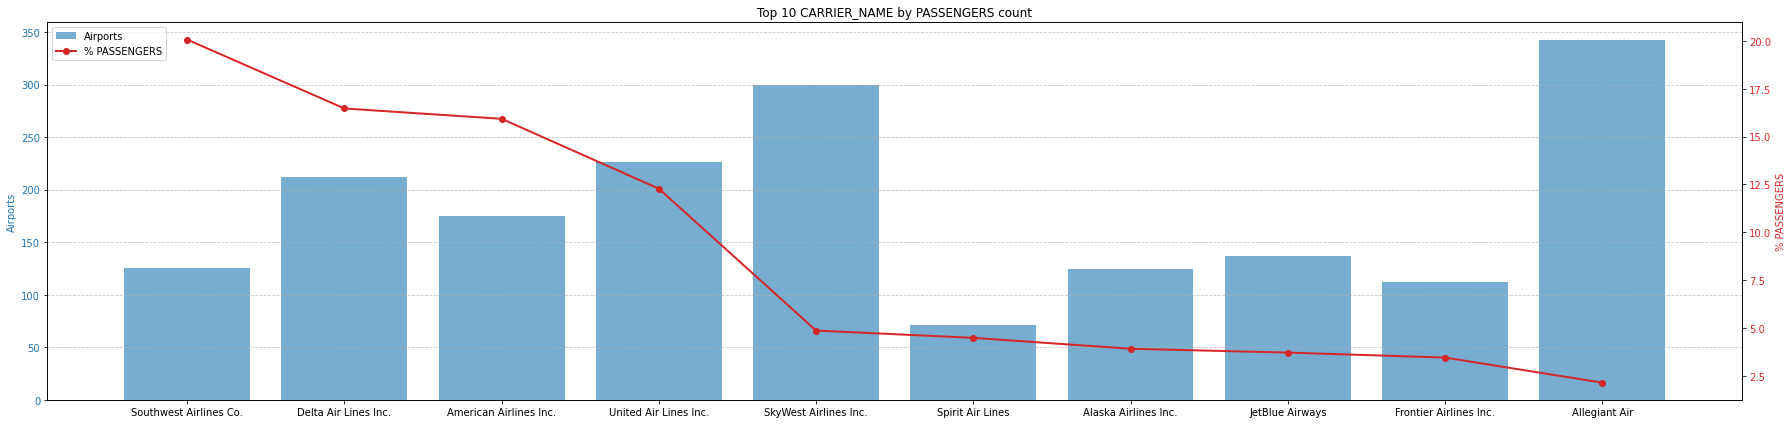

In [22]:
top_10_plot(df_carrier,'CARRIER_NAME','Airports','% Total')

- The market is dominated by **Big Four** major US airlines (Southwest, Delta, American, and United) accounting for **~65%** of the total passenger volume.

- **Southwest Airlines Co.** is the market leader, responsible for **20%** of all passengers, slightly ahead of the second-place carrier.

- The cumulative share of the **top three carriers** (Southwest, Delta, and American) is **52%**, suggesting that nearly half the passenger base is served by the three largest operators.
- The chart shows that the number of airports served does not necessarily equate to passenger volume dominance, probably becasue their route strategies are different.


### 2.4.2 Top 10 States sorted by Passengers count

In [23]:
df_state = passenger_pct('ORIGIN_STATE_NM')

df_state.reset_index(drop=True).head(10)

,ORIGIN_STATE_NM,PASSENGERS,% Total,Cumulative % Total,Airports,Airlines
0,California,318692770,10.91,10.91,109,60
1,Florida,309169476,10.58,21.49,77,66
2,Texas,307341565,10.52,32.01,83,65
3,Georgia,165064315,5.65,37.66,38,59
4,Illinois,146562488,5.02,42.68,23,61
5,Colorado,137568729,4.71,47.39,24,54
6,New York,134643516,4.61,52.00,60,67
7,North Carolina,120840734,4.14,56.14,34,58
8,Nevada,99597072,3.41,59.55,18,51
9,Arizona,93126601,3.19,62.74,41,63


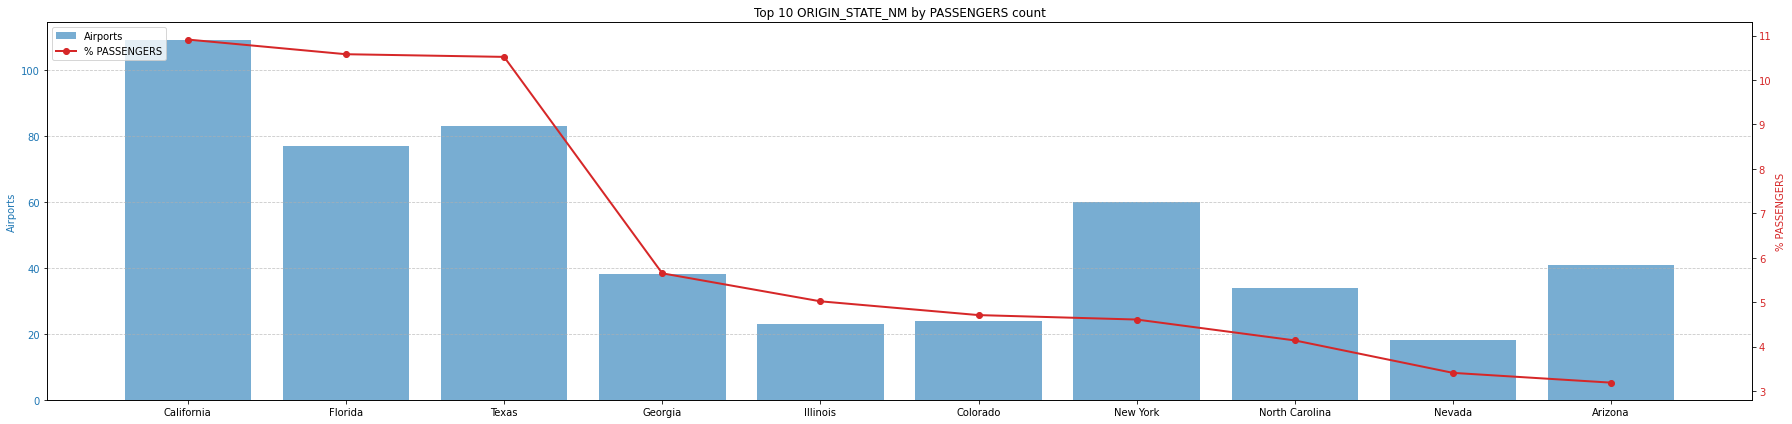

In [24]:
top_10_plot(df_state,'ORIGIN_STATE_NM','Airports','% Total')

The table ranks US states by the total number of originating passengers.

- Passenger origination is highly concentrated, with the **top five states** generating nearly **42%** of the total passenger volume.

- The **top three states** (California, Florida, and Texas) collectively generate over a third of the traffic, accounting for **32%** of the total originating passengers - also having the highest number of airports.



### 2.4.3 Top 10 Cities sorted by Passengers count

In [25]:
df_city = passenger_pct('ORIGIN_CITY_NAME')

df_city.reset_index(drop=True).head(10)

,ORIGIN_CITY_NAME,PASSENGERS,% Total,Cumulative % Total,Airports,Airlines
0,"Atlanta, GA",156422427,5.35,5.35,3,52
1,"Chicago, IL",142096420,4.86,10.21,4,59
2,"Denver, CO",127384265,4.36,14.57,3,50
3,"Dallas/Fort Worth, TX",121314866,4.15,18.72,4,59
4,"New York, NY",103861299,3.55,22.27,6,47
5,"Las Vegas, NV",91418871,3.13,25.40,4,48
6,"Los Angeles, CA",91293497,3.12,28.52,1,48
7,"Charlotte, NC",85341817,2.92,31.44,1,44
8,"Phoenix, AZ",85209473,2.92,34.36,4,54
9,"Orlando, FL",84999204,2.91,37.27,3,53


- Out of ~1450 cities the **top 5** generate nearly **22%** of the passenger traffic.

- The **top 2** collectively generate **10%** of passenger volume.


### 2.4.4 Top 10 Oirg-Dest CITY routes sorted by Passengers count

In [26]:
# Assing same name for "A to B" and "B to A" travel
df['OD_city_pair'] = np.where(
    df['ORIGIN_CITY_NAME'] <= df['DEST_CITY_NAME'],
    df['ORIGIN_CITY_NAME'].astype(str) + " & " + df['DEST_CITY_NAME'].astype(str),
    df['DEST_CITY_NAME'].astype(str) + " & " + df['ORIGIN_CITY_NAME'].astype(str)
)

df_city_pair = passenger_pct('OD_city_pair')

# Average distance
avg_distance = df.groupby('OD_city_pair')['DISTANCE'].mean().astype(int)
df_city_pair = df_city_pair.merge(avg_distance, on='OD_city_pair', how='left')


df_city_pair.reset_index(drop=True).head(10)

,OD_city_pair,PASSENGERS,% Total,Cumulative % Total,Airports,Airlines,DISTANCE
0,"Miami, FL & New York, NY",12565694,0.43,0.43,4,23,1092
1,"Chicago, IL & New York, NY",12334770,0.42,0.85,5,22,735
2,"Atlanta, GA & New York, NY",11758189,0.40,1.25,4,16,761
3,"New York, NY & Orlando, FL",10685543,0.37,1.62,3,10,948
4,"Chicago, IL & Denver, CO",10118853,0.35,1.97,4,16,890
5,"Los Angeles, CA & New York, NY",10051699,0.34,2.31,3,13,2473
6,"Atlanta, GA & Orlando, FL",10010953,0.34,2.65,4,20,404
7,"Chicago, IL & Los Angeles, CA",9706406,0.33,2.98,4,22,1745
8,"Fort Lauderdale, FL & New York, NY",9360419,0.32,3.30,3,10,1073
9,"Las Vegas, NV & Los Angeles, CA",9290550,0.32,3.62,3,27,235


The table identifies the busiest city-pair routes.

- **New York** dominates as top Origin/Destination city, featuring **six times** in the top ten busiest city pairs.

- The top ten also features the **longest route** between Los Angeles, CA, and New York, NY, a major transcontinental corridor.

- The cumulative share of the **top ten city-pair** routes is **only 3.5%**, indicating that **passenger volume is distributed** across a massive number of unique flight paths.



### 2.4.5 Distance Group sorted by Passengers count

In [27]:
df_dist_grp = passenger_pct('DISTANCE_GROUP')

# Distance Range
min_distance = df.groupby('DISTANCE_GROUP')['DISTANCE'].min().astype(int).reset_index(name='Min_Dist')
max_distance = df.groupby('DISTANCE_GROUP')['DISTANCE'].max().astype(int).reset_index(name='Max_Dist')

df_dist_grp = df_dist_grp.merge(min_distance, on='DISTANCE_GROUP', how='left')
df_dist_grp = df_dist_grp.merge(max_distance, on='DISTANCE_GROUP', how='left')

df_dist_grp['Distance_Range'] = df_dist_grp['Min_Dist'].astype(str) + " - " + df_dist_grp['Max_Dist'].astype(str)

df_dist_grp.reset_index(drop=True).drop(columns = ['Min_Dist','Max_Dist']).head(10)

,DISTANCE_GROUP,PASSENGERS,% Total,Cumulative % Total,Airports,Airlines,Distance_Range
0,2,1051754883,35.99,35.99,861,85,500 - 999
1,1,816321115,27.94,63.93,1492,119,0 - 499
2,3,553747777,18.95,82.88,620,65,1000 - 1499
3,4,250881327,8.59,91.47,478,56,1500 - 1999
4,5,162207922,5.55,97.02,324,53,2000 - 2499
5,6,75037813,2.57,99.59,148,45,2500 - 2999
6,8,4208798,0.14,99.73,53,23,3501 - 3993
7,7,3687489,0.13,99.86,67,24,3016 - 3498
8,10,2197972,0.08,99.94,34,18,4502 - 4983
9,9,1637090,0.06,100.00,20,20,4004 - 4475


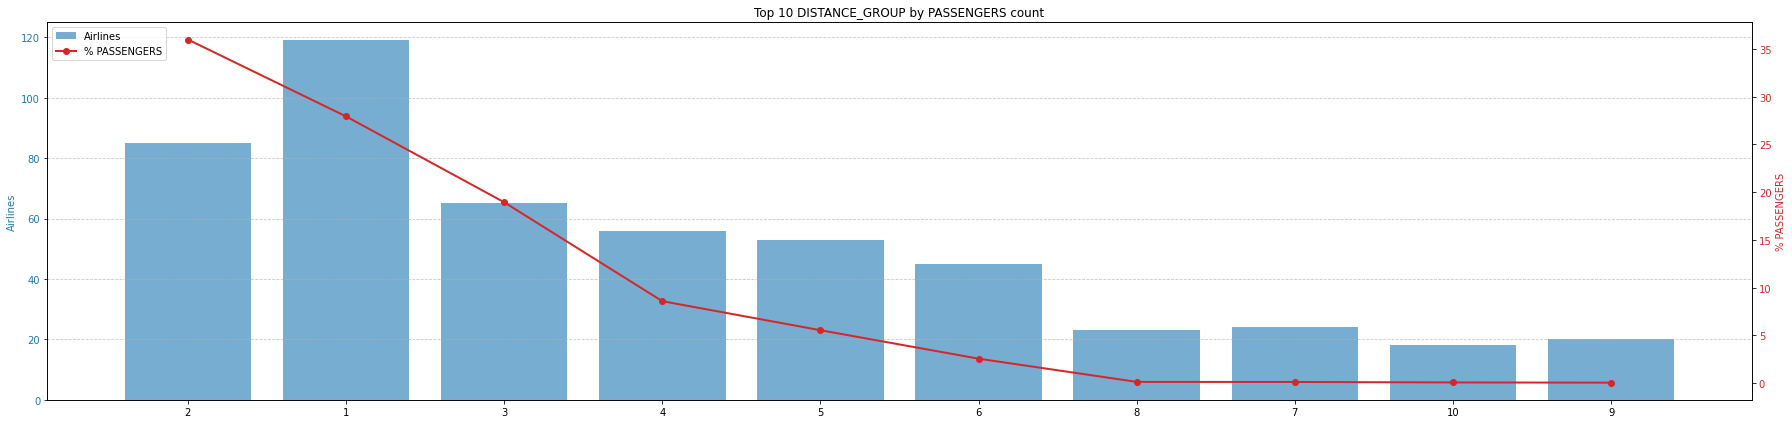

In [28]:
top_10_plot(df_dist_grp,'DISTANCE_GROUP','Airlines','% Total')

The table ranks the total passengers aggregated by distance group.

- The **shortest distance groups** (Group 1 & 2) account for **~65%** of all passengers, utilizing the widest network of airports & airlines.

- There is a **steep drop-off** in passenger volume as the distance group increases, with very little traffic volume remaining in the **longest-haul groups**.

- As the distance group increases, the number of unique airports served & airlines operating decreases, indicating that long-haul traffic is highly concentrated to a much smaller set of major hub airports & airlines.

## 2.5 Feature Engineering

In [29]:
df_grp = df.groupby('DATE', as_index=False)['PASSENGERS'].sum()
df_grp = df_grp.set_index('DATE').asfreq('MS') # MS = month start

df_grp = df_grp.sort_index()

# Extract month,year & quarter numbers 
df_grp['month'] = df_grp.index.month
df_grp['year'] = df_grp.index.year
df_grp['quarter'] = df_grp.index.quarter


# Create Season Feature
def month_to_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:  # 9, 10, 11
        return 'Fall'

df_grp['season'] = df_grp['month'].apply(month_to_season)

# Apply One-Hot Encoding
season_dummies = pd.get_dummies(df_grp['season'], prefix='season', dtype=int)

### 2.5.1 Time Series Features

In [30]:
# --- Autoregressive (AR) ---
for lag in [1, 3, 6, 12]:
    df_grp[f'lag_{lag}'] = df_grp['PASSENGERS'].shift(lag)
    

# --- Moving Averages (MA) ----

from scipy.stats import linregress

# Define the custom slope function
def calculate_rolling_slope(series):
    # This function uses the index position (0, 1, 2, ...) as the independent variable X
    if len(series) < 2 or series.isnull().sum() > (len(series) - 2):
        return np.nan
        
    x = np.arange(len(series))
    slope, _, _, _, _ = linregress(x, series.values)
    return slope

# shift by 1 time period to avoid data leakage during forecasting
for window in [3, 6, 12]:
    df_grp[f'rolling_mean_{window}'] = df_grp['PASSENGERS'].shift(1).rolling(window).mean()
    df_grp[f'rolling_std_{window}'] = df_grp['PASSENGERS'].shift(1).rolling(window).std()
    df_grp[f'rolling_min_{window}'] = df_grp['PASSENGERS'].shift(1).rolling(window).min()
    df_grp[f'rolling_max_{window}'] = df_grp['PASSENGERS'].shift(1).rolling(window).max()
    df_grp[f'rolling_trend_{window}'] = df_grp['PASSENGERS'].shift(1) - df_grp[f'rolling_mean_{window}']
    df_grp[f'rolling_slope_{window}'] = (df_grp['PASSENGERS'].shift(1).rolling(window=window, min_periods=window).apply(calculate_rolling_slope, raw=False))
    

# --- Differencing (Transformation to induce Stationarity) ----
for diff in [1, 3, 6, 12]:
    df_grp[f'diff_{diff}'] = df_grp['PASSENGERS'].diff(diff)

    
df_grp.tail(5)

,PASSENGERS,month,year,quarter,season,lag_1,lag_3,lag_6,lag_12,rolling_mean_3,rolling_std_3,rolling_min_3,rolling_max_3,rolling_trend_3,rolling_slope_3,rolling_mean_6,rolling_std_6,rolling_min_6,rolling_max_6,rolling_trend_6,rolling_slope_6,rolling_mean_12,rolling_std_12,rolling_min_12,rolling_max_12,rolling_trend_12,rolling_slope_12,diff_1,diff_3,diff_6,diff_12
DATE,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-03-01,72498050.0,3,2025,1,Spring,58438666.0,72350347.0,68306882.0,73481522.0,6.380096e+07,7.483444e+06,58438666.0,72350347.0,-5.362289e+06,-6955840.5,6.684570e+07,6.096964e+06,58438666.0,73372639.0,-8.407035e+06,-2.378826e+06,7.106726e+07,6.337738e+06,58438666.0,78990228.0,-1.262859e+07,-1.236069e+06,14059384.0,147703.0,4191168.0,-983472.0
2025-04-01,69851898.0,4,2025,2,Spring,72498050.0,60613852.0,73372639.0,70799807.0,6.385019e+07,7.567825e+06,58438666.0,72498050.0,8.647861e+06,5942099.0,6.754423e+07,6.523055e+06,58438666.0,73372639.0,4.953821e+06,-1.279112e+06,7.098530e+07,6.309978e+06,58438666.0,78990228.0,1.512751e+06,-1.071300e+06,-2646152.0,9238046.0,-3520741.0,-947909.0
2025-05-01,74483981.0,5,2025,2,Spring,69851898.0,58438666.0,67991822.0,76044234.0,6.692954e+07,7.471393e+06,58438666.0,72498050.0,2.922360e+06,5706616.0,6.695744e+07,6.033908e+06,58438666.0,72498050.0,2.894459e+06,2.162372e+05,7.090631e+07,6.318439e+06,58438666.0,78990228.0,-1.054409e+06,-1.123323e+06,4632083.0,16045315.0,6492159.0,-1560253.0
2025-06-01,76538599.0,6,2025,2,Summer,74483981.0,72498050.0,72350347.0,77377452.0,7.227798e+07,2.323870e+06,69851898.0,74483981.0,2.206005e+06,992965.5,6.803947e+07,6.791089e+06,58438666.0,74483981.0,6.444515e+06,1.498334e+06,7.077629e+07,6.218360e+06,58438666.0,78990228.0,3.707695e+06,-7.521783e+05,2054618.0,4040549.0,4188252.0,-838853.0
2025-07-01,79065585.0,7,2025,3,Summer,76538599.0,69851898.0,60613852.0,78990228.0,7.362483e+07,3.425143e+06,69851898.0,76538599.0,2.913773e+06,3343350.5,6.873751e+07,7.500966e+06,58438666.0,76538599.0,7.801091e+06,3.574672e+06,7.070638e+07,6.141648e+06,58438666.0,78990228.0,5.832218e+06,-2.304979e+05,2526986.0,9213687.0,18451733.0,75357.0


**Autoregressive (AR) Lag Features:**
- Lagged passenger demand (e.g., lag 1, 3, 6, 12 months) captures trends and repeated patterns, letting the model learn from historical demand to forecast future values.
- Long lags (e.g., 12 months) detect annual seasonality.
- Short lags (1–3 months) help identify momentum or recency effects such as short-term dips or spikes.

**Moving Averages (MA) and Rolling Window Features:**
- Rolling means and standard deviations over various windows smooth out short-term fluctuations, enabling the model to focus on persistent trends rather than noise.
- Rolling min and max provide boundaries of historical demand, helping detect anomalies or shifts in passenger behavior.
- Rolling trend and slope features quantify demand growth or decline directionally, useful for capturing changing trends over time and for early warning of up or down shifts.

**Differencing (Transformation to induce Stationarity):**
- Differencing across 1, 3, 6, or 12 periods removes non-stationarity in time series, making passenger demand more suitable for many forecasting algorithms and statistical analysis.

### 2.5.2 Categorical Features

In [31]:
# --- Top Carrier Share (Create binary columns) ---
top_carriers = ['Southwest Airlines Co.', 'Delta Air Lines Inc.', 'American Airlines Inc.', 'United Air Lines Inc.', 'SkyWest Airlines Inc.']

df_carrier_share = (
    df.groupby(['DATE', 'CARRIER_NAME'])['PASSENGERS'].sum()
    .unstack(fill_value=0)
    .apply(lambda x: x / x.sum(), axis=1) # Calculate share of total monthly passengers
    [top_carriers] # Select only the top carriers
)
# Rename columns for clarity (e.g., SW_Share, DL_Share)
df_carrier_share.columns = [col.split(' ')[0] + '_Share' for col in df_carrier_share.columns]



# --- Top States Share (Target Encoding) ---
top_states = ['California', 'Texas', 'Florida']

df_state_share = (
    df.groupby(['DATE', 'ORIGIN_STATE_NM'])['PASSENGERS'].sum()
    .unstack(fill_value=0)
    .apply(lambda x: x / x.sum(), axis=1)
    [top_states]
)
df_state_share.columns = [col + '_Share' for col in df_state_share.columns]



# --- Distance Group Share (Ordinal Encoding) ---
top_dist_grp = ['1','2']

df_dist_share = (
    df.groupby(['DATE', 'DISTANCE_GROUP'])['PASSENGERS'].sum()
    .unstack(fill_value=0)
    .apply(lambda x: x / x.sum(), axis=1)
    [top_dist_grp]
)
df_dist_share.columns = ['DG_' + col + '_Share' for col in df_dist_share.columns]

- **Carrier Share**: Allows the model to learn if changes in the aggregate total are driven by the cyclical or strategic behavior of the dominant market players.

- **State Share**: Enables the model to associate overall demand with the travel propensity of the most important traffic-generating regions.

- **Distance Group Share**: Allows the model to account for shifts in the mix of short-haul versus long-haul travel, which could influence overall aggregate passenger volume.

### 2.5.3 Merge all Features

In [32]:
df_merge = pd.merge(df_grp, df_carrier_share, on=['DATE'], how='left')
df_merge = pd.merge(df_merge, df_state_share, on=['DATE'], how='left')
df_merge = pd.merge(df_merge, df_dist_share, on=['DATE'], how='left')

# Concatenate the new columns back to the original DataFrame
df_ts = pd.concat([df_merge.drop('season', axis=1), season_dummies], axis=1)

df_ts.tail(5)

,PASSENGERS,month,year,quarter,lag_1,lag_3,lag_6,lag_12,rolling_mean_3,rolling_std_3,rolling_min_3,rolling_max_3,rolling_trend_3,rolling_slope_3,rolling_mean_6,rolling_std_6,rolling_min_6,rolling_max_6,rolling_trend_6,rolling_slope_6,rolling_mean_12,rolling_std_12,rolling_min_12,rolling_max_12,rolling_trend_12,rolling_slope_12,diff_1,diff_3,diff_6,diff_12,Southwest_Share,Delta_Share,American_Share,United_Share,SkyWest_Share,California_Share,Texas_Share,Florida_Share,DG_1_Share,DG_2_Share,season_Fall,season_Spring,season_Summer,season_Winter
DATE,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-03-01,72498050.0,3,2025,1,58438666.0,72350347.0,68306882.0,73481522.0,6.380096e+07,7.483444e+06,58438666.0,72350347.0,-5.362289e+06,-6955840.5,6.684570e+07,6.096964e+06,58438666.0,73372639.0,-8.407035e+06,-2.378826e+06,7.106726e+07,6.337738e+06,58438666.0,78990228.0,-1.262859e+07,-1.236069e+06,14059384.0,147703.0,4191168.0,-983472.0,0.196034,0.160338,0.151864,0.125776,0.050401,0.103067,0.102883,0.122678,0.268299,0.356980,0,1,0,0
2025-04-01,69851898.0,4,2025,2,72498050.0,60613852.0,73372639.0,70799807.0,6.385019e+07,7.567825e+06,58438666.0,72498050.0,8.647861e+06,5942099.0,6.754423e+07,6.523055e+06,58438666.0,73372639.0,4.953821e+06,-1.279112e+06,7.098530e+07,6.309978e+06,58438666.0,78990228.0,1.512751e+06,-1.071300e+06,-2646152.0,9238046.0,-3520741.0,-947909.0,0.194850,0.164766,0.156099,0.123865,0.051569,0.107010,0.100840,0.116052,0.276603,0.357533,0,1,0,0
2025-05-01,74483981.0,5,2025,2,69851898.0,58438666.0,67991822.0,76044234.0,6.692954e+07,7.471393e+06,58438666.0,72498050.0,2.922360e+06,5706616.0,6.695744e+07,6.033908e+06,58438666.0,72498050.0,2.894459e+06,2.162372e+05,7.090631e+07,6.318439e+06,58438666.0,78990228.0,-1.054409e+06,-1.123323e+06,4632083.0,16045315.0,6492159.0,-1560253.0,0.195782,0.167235,0.157692,0.126284,0.052878,0.106444,0.105282,0.102109,0.282797,0.362805,0,1,0,0
2025-06-01,76538599.0,6,2025,2,74483981.0,72498050.0,72350347.0,77377452.0,7.227798e+07,2.323870e+06,69851898.0,74483981.0,2.206005e+06,992965.5,6.803947e+07,6.791089e+06,58438666.0,74483981.0,6.444515e+06,1.498334e+06,7.077629e+07,6.218360e+06,58438666.0,78990228.0,3.707695e+06,-7.521783e+05,2054618.0,4040549.0,4188252.0,-838853.0,0.195923,0.165416,0.155896,0.125913,0.052985,0.109487,0.105048,0.095647,0.273414,0.364226,0,0,1,0
2025-07-01,79065585.0,7,2025,3,76538599.0,69851898.0,60613852.0,78990228.0,7.362483e+07,3.425143e+06,69851898.0,76538599.0,2.913773e+06,3343350.5,6.873751e+07,7.500966e+06,58438666.0,76538599.0,7.801091e+06,3.574672e+06,7.070638e+07,6.141648e+06,58438666.0,78990228.0,5.832218e+06,-2.304979e+05,2526986.0,9213687.0,18451733.0,75357.0,0.193156,0.165314,0.155382,0.127043,0.053009,0.106837,0.103821,0.094442,0.271508,0.363682,0,0,1,0


### 2.6 Feature Importance
To quantify the predictive power of each variable and select the most informative features

In [33]:
from sklearn.ensemble import RandomForestRegressor

# --- Prepare Data for Modeling ---
features = df_ts.drop(columns=['PASSENGERS','month','year','quarter']).columns.tolist()
target = 'PASSENGERS'

df_imp = df_ts.dropna()

X = df_imp[features]
y = df_imp[target]

# --- Train a Random Forest Regressor to get feature importance ---
model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, max_depth=5)
model.fit(X, y)

importances = model.feature_importances_
feature_names = X.columns

df_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

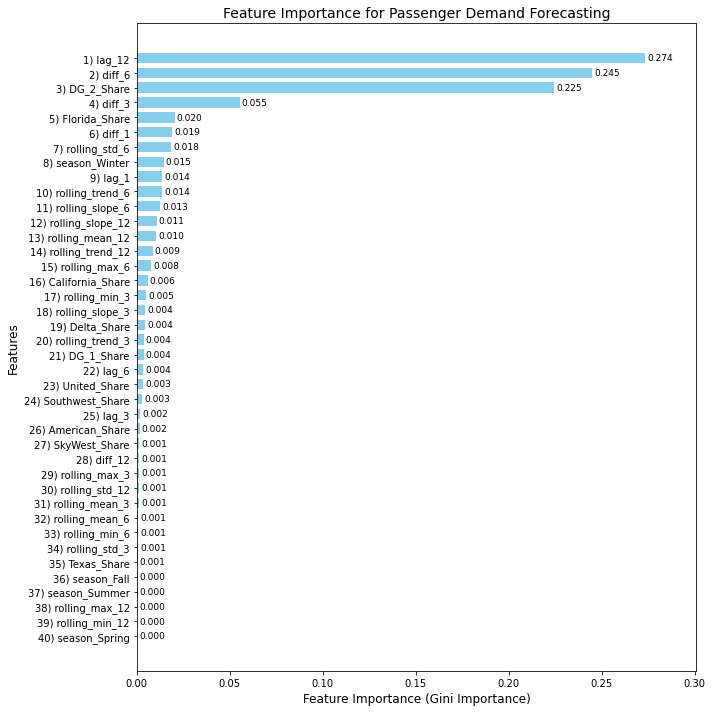

In [34]:
# --- Sort & Plot ---
df_importance = df_importance.sort_values(by='Importance', ascending=False).reset_index(drop=True)

df_importance['Label'] = (df_importance.index + 1).astype(str) + ") " + df_importance['Feature']


# Reverse the order for plotting (horizontal bar charts usually plot from bottom up)
df_importance = df_importance.sort_values(by='Importance', ascending=True).reset_index(drop=True)

plt.figure(figsize=(10, 10))

bars = plt.barh(df_importance['Label'], df_importance['Importance'], color='skyblue', height=0.7)

plt.xlabel("Feature Importance (Gini Importance)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.title("Feature Importance for Passenger Demand Forecasting", fontsize=14)

for bar in bars:
    # Get the width of the bar (the x-value)
    width = bar.get_width()
    
    plt.text(
        width + 0.001, # x position: end of the bar + small padding
        bar.get_y() + bar.get_height()/2, # y position: center of the bar
        f'{width:.3f}', # Formatted importance value (3 decimal places)
        ha='left',      # Horizontal alignment: left (starts after the bar)
        va='center',    # Vertical alignment: center
        fontsize=9
    )

# Adjust plot limits to make space for the labels
plt.xlim(0, max(df_importance['Importance']) * 1.1) 

plt.tight_layout()
plt.show()

**Top Features Dominate Prediction**

- The most important features are time series-based: **lag_12, diff_6, and DG_2_Share**, contributing 27.4%, 24.5%, and 22.5% of total importance, respectively.
- Collectively, these **top three features** explain over **74%** of the total model importance, showing significant predictive power.


**Lag Features Are Critical**

- Lag features (lag_12, lag_1, lag_6) and differenced values (diff_6, diff_3, diff_1) dominate the importance rankings indicating past values and their changes are highly informative for forecasting future demand.


**Business and Categorical Features Play a Secondary Role**

- Some **market share features** (e.g., Florida_Share, California_Share, Delta_Share) appear among the more relevant predictors, though their individual importances are much lower (~0.02 or less) compared to the top time series features, indicating carrier-specific effects are present but play a secondary role to autoregressive factors.

- Other share or seasonal variables, such as **season_Winter**, carry minor predictive value unless they interact with more dominant lag/rolling features.


**Long Tail of Low-Value Features**

- The bottom half (from rolling_mean_12 downward) have feature importances at or **below 0.01**, with many at or near zero, suggesting very limited incremental value and potential redundancy.

**2.6.1 Retaining only features with importance above 0.01**

In [35]:
imp_threshold = 0.009

df_importance = df_importance.sort_values(by='Importance', ascending=False).reset_index(drop=True)

top_features = df_importance.query(f'Importance > {imp_threshold}')['Feature'].tolist()

### 2.7 Correlation Heatmap
To identify highly correlated feature pairs (redundancy) and features that are strongly correlated with the target, enabling the removal of multicollinear features and prioritizing the most relevant variables for model input.

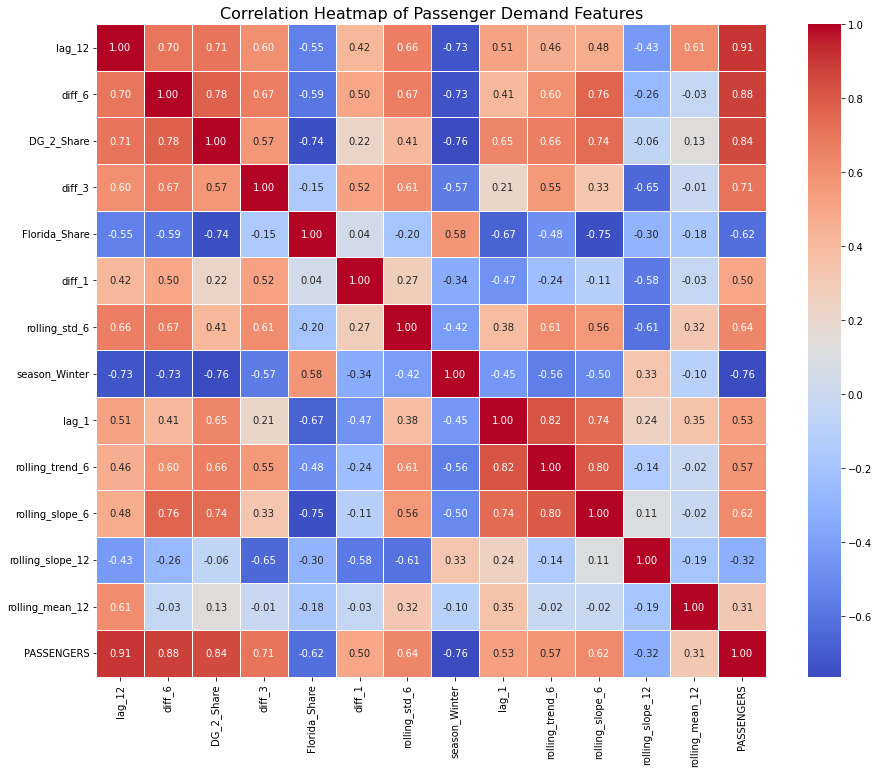

In [36]:
corr_matrix = df_imp[top_features + ['PASSENGERS']].corr()

# --- Correlation Heatmap ---
plt.figure(figsize=(15,12))
sns.heatmap(
    corr_matrix, 
    annot=True,          # Show the correlation values on the heatmap
    fmt=".2f",           # Format the values to two decimal places
    cmap='coolwarm',     # Color map (coolwarm is excellent for showing positive/negative correlation)
    linewidths=.5,       # Add lines between cells for clarity
    cbar=True            # Show the color bar
)

plt.title('Correlation Heatmap of Passenger Demand Features', fontsize=16)
plt.show()

**High Target Correlation:**
- Features like **lag_12 (0.91), diff_6 (0.88), and DG_2_Share (0.84)** have strong positive correlation with **PASSENGERS**, validating their selection as key drivers of demand.


**High Inter-Feature Correlations:**
- There are several feature pairs with correlations above 0.8 like,
 - lag_1 vs rolling_trend_6 (0.82)
 - rolling_trend_6 vs. rolling_slope_6 (0.8)
- These strong relationships signal notable redundancy or collinearity.


**Negative Correlations:**
- Features like **season_Winter** show strong negative relationships with both other features (e.g., -0.76 with DG_2_Share) and the target (-0.76 with "PASSENGERS"). This supports its value for capturing non-linear or out-of-phase patterns.

### 2.8 Pruning
Excluding features with very high Inter-Feature correlation (> 0.8) and very low correlation with Target (< 0.5).

In [37]:
target = 'PASSENGERS'

# Calculate absolute correlation matrix
corr_matrix = df_imp[top_features + ['PASSENGERS']].corr().abs()

# Select features with correlation > 0.5 with the target
target_corr = corr_matrix[target]
selected_features = target_corr[target_corr > 0.5].index.drop(target)

# Subset correlation matrix to only these selected features
corr_sub_matrix = corr_matrix.loc[selected_features, selected_features]

# Find features with any correlation > 0.8 with other features
upper = corr_sub_matrix.where(np.triu(np.ones(corr_sub_matrix.shape), k=1).astype(bool))
high_corr_features = [col for col in upper.columns if any(upper[col] > 0.8)]

### 2.9 Final list of Features to be selected

In [38]:
# Final feature list excludes highly correlated features
final_feats = [feat for feat in selected_features if feat not in high_corr_features]

df_importance.query(f'Feature == {final_feats}').drop(columns='Label').head(20)

,Feature,Importance
0,lag_12,0.273589
1,diff_6,0.244930
2,DG_2_Share,0.224591
3,diff_3,0.055468
4,Florida_Share,0.020411
6,rolling_std_6,0.018419
7,season_Winter,0.014516
8,lag_1,0.013705
10,rolling_slope_6,0.012542


### 2.10 Final dataset

In [39]:
df_final = df_ts[['PASSENGERS','month','year','quarter'] + final_feats]

df_final.tail(12)

,PASSENGERS,month,year,quarter,lag_12,diff_6,DG_2_Share,diff_3,Florida_Share,rolling_std_6,season_Winter,lag_1,rolling_slope_6
DATE,,,,,,,,,,,,,
2024-08-01,75039612.0,8,2024,3,71756007.0,13836666.0,0.363568,-1004622.0,0.090031,6.458385e+06,0,78990228.0,3.024818e+06
2024-09-01,68306882.0,9,2024,3,67202179.0,-5174640.0,0.361584,-9070570.0,0.084766,2.902176e+06,0,75039612.0,9.627123e+05
2024-10-01,73372639.0,10,2024,4,73355765.0,2572832.0,0.360846,-5617589.0,0.083290,4.077532e+06,0,68306882.0,-3.961633e+05
2024-11-01,67991822.0,11,2024,4,68720117.0,-8052412.0,0.361411,-7047790.0,0.103533,3.741296e+06,0,73372639.0,-1.272009e+06
2024-12-01,72350347.0,12,2024,4,68162621.0,-5027105.0,0.357100,4043465.0,0.106838,4.579767e+06,1,67991822.0,-2.014676e+06
2025-01-01,60613852.0,1,2025,1,60026644.0,-18376376.0,0.350375,-12758787.0,0.122529,4.173205e+06,1,72350347.0,-1.407915e+06
2025-02-01,58438666.0,2,2025,1,61202946.0,-16600946.0,0.352359,-9553156.0,0.121573,5.222928e+06,1,60613852.0,-1.867978e+06
2025-03-01,72498050.0,3,2025,1,73481522.0,4191168.0,0.356980,147703.0,0.122678,6.096964e+06,0,58438666.0,-2.378826e+06
2025-04-01,69851898.0,4,2025,2,70799807.0,-3520741.0,0.357533,9238046.0,0.116052,6.523055e+06,0,72498050.0,-1.279112e+06


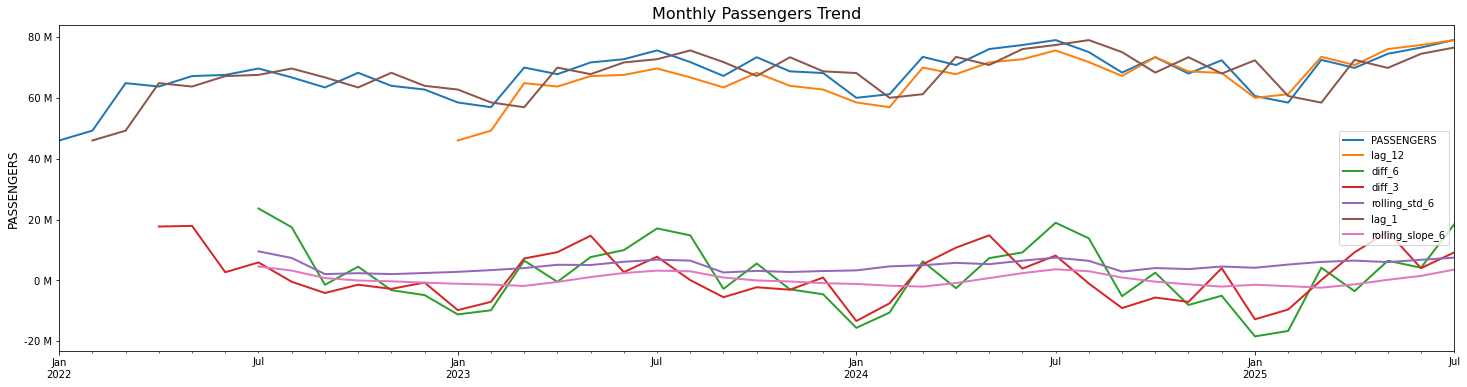

In [40]:
df_plot = df_final.drop(columns = ['year','month','quarter','DG_2_Share','Florida_Share','season_Winter'])

df_plot.plot(kind='line', figsize=(25,6), ax=plt.gca(), linewidth=2) # Use 'ax=plt.gca()' to plot on the current figure

# Define a function to format the y-axis tick labels
def millions_formatter(x, pos):
    """The two args are the value and tick position."""
    # Divide by 1,000,000 and append 'M'
    return f'{x/1000000:.0f} M'

# Apply the custom formatter to the y-axis
formatter = ticker.FuncFormatter(millions_formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.title('Monthly Passengers Trend', fontsize=16)
plt.xlabel('')
plt.ylabel('PASSENGERS', fontsize=12)
plt.legend(title='', loc='right')


plt.show()

- Features based on lags (especially lag_12) consistently move with the passenger series, reinforcing their importance for forecasting and their highly linear relationships.
- Differencing features (diff_6, diff_3) highlight change points and may assist in informing the model of abrupt shifts, regime changes, or seasonal effects.
- Rolling window metrics like rolling_std_6 and rolling_slope_6 trend upward, which may inform a model of increasing variability and underlying trend strength.

------------------------------------------------------------------------------------

# 3. Modeling & Inferencing

In [41]:
from sklearn.metrics import mean_absolute_error

# Split into train and test (last N months for test)
n_test = 7

train, test = df_final.iloc[:-n_test], df_final.iloc[-n_test:]

### 3.1 Baseline Models

In [42]:
# 1. Naive Forecast (Last observed value)
test['naive_forecast'] = train['PASSENGERS'].iloc[-1]

# 2. Moving Average
test['movavg_forecast'] = train['PASSENGERS'].rolling(window).mean().iloc[-1]

# 3. Seasonal Naive (Value from same month last year)
test['seasonal_naive'] = test['lag_12']

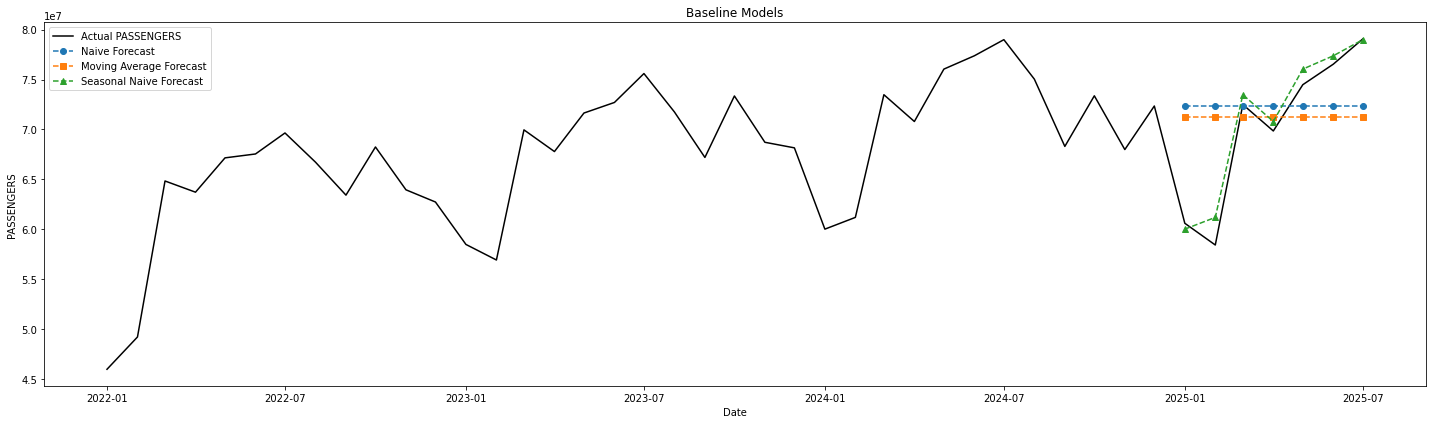

In [43]:
plt.figure(figsize=(20,6))
plt.plot(df_final.index, df_final['PASSENGERS'], label='Actual PASSENGERS', color='black')
plt.plot(test.index, test['naive_forecast'], label='Naive Forecast', linestyle='--', marker='o')
plt.plot(test.index, test['movavg_forecast'], label='Moving Average Forecast', linestyle='--', marker='s')
plt.plot(test.index, test['seasonal_naive'], label='Seasonal Naive Forecast', linestyle='--', marker='^')

plt.xlabel('Date')
plt.ylabel('PASSENGERS')
plt.title('Baseline Models')
plt.legend()
plt.tight_layout()
plt.show()

- The **Seasonal Naive Forecast** is the strongest among the baselines, showing good alignment with the real seasonal turns of passenger demand, but still underestimates the amplitude of recent increases.

- Both the **Naive** and **Moving Average** forecasts are outperformed, as they cannot anticipate seasonal fluctuations or trending changes in the data.

- The plot confirms that accounting for seasonality is crucial in passenger demand forecasting—seasonal naivety provides a competitive and interpretable baseline for model evaluation.

- Advanced models should, at minimum, match the Seasonal Naive baseline and are expected to improve by learning trend and amplitude changes beyond simple seasonal repetition. The actual data's seasonal structure must be captured to deliver meaningful passenger forecasts.

### 3.2 Classical Statistical Models

Based on the ACF and PACF plots, the following ARIMA and SARIMA hyperparameters will be used:

**ARIMA (p, d, q)**
- p (AR order): 1 (Strong PACF spike at lag 1, then cuts off)

- d (Differencing): 1 (First differencing is required because series shows trend and is non-stationary)

- q (MA order): 0 or 1 ("ACF" cuts off quickly after lag 1, test for 0 or 1)

Recommended: (p, d, q) = (1, 1, 0) or (1, 1, 1)

**SARIMA (P, D, Q, s)**
- P (Seasonal AR order): 1 (Large spikes at seasonal lag 12 in both ACF and PACF)

- D (Seasonal differencing): 1 (Annual seasonality and likely seasonal trend)

- Q (Seasonal MA order): 0 or 1 (Seasonal ACF at lag 12, so start with 0 or 1)

- s (Seasonal period): 12 (For monthly data, s = 12)

Recommended: (P, D, Q, s) = (1, 1, 0, 12) or (1, 1, 1, 12)

In [44]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# 4. ARIMA Model (choose (p,d,q) based on ACF/PACF)
arima_order = (1, 1, 1)
arima_model = ARIMA(train['PASSENGERS'], order=arima_order)
arima_fit = arima_model.fit()
arima_forecast = arima_fit.forecast(steps=n_test)


# 5.1 SARIMA Model (choose (p,d,q) and (P,D,Q,s) for seasonality)
sarima_order = (1, 1, 0)
sarima_seasonal_order = (1, 1, 0, 12)  # Monthly seasonality: s=12
sarima_model = SARIMAX(train['PASSENGERS'], order=sarima_order, seasonal_order=sarima_seasonal_order)
sarima_fit = sarima_model.fit(disp=False)
sarima_forecast = sarima_fit.forecast(steps=n_test)


# 5.2 SARIMA Model (choose (p,d,q) and (P,D,Q,s) for seasonality)
sarima_order_2 = (1, 1, 1)
sarima_seasonal_order_2 = (1, 1, 1, 12)
sarima_model_2 = SARIMAX(train['PASSENGERS'], order=sarima_order_2, seasonal_order=sarima_seasonal_order_2)
sarima_fit_2 = sarima_model_2.fit(disp=False)
sarima_forecast_2 = sarima_fit_2.forecast(steps=n_test)

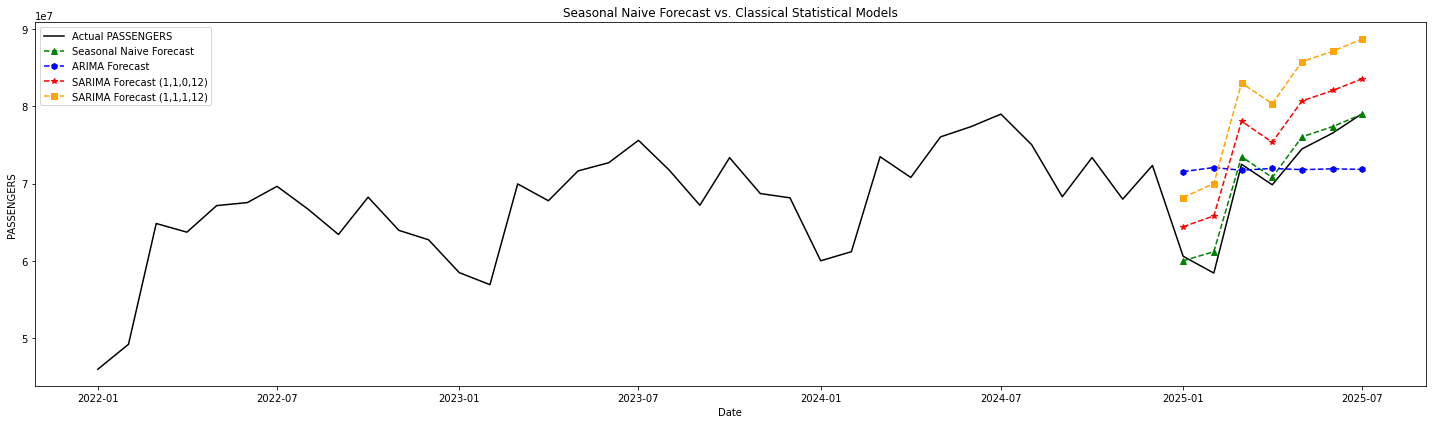

In [45]:
plt.figure(figsize=(20,6))
plt.plot(df_final.index, df_final['PASSENGERS'], label='Actual PASSENGERS', color='black')
plt.plot(test.index, test['seasonal_naive'], label='Seasonal Naive Forecast', linestyle='--', marker='^', color='green')
plt.plot(test.index, arima_forecast, label='ARIMA Forecast', linestyle='--', marker='h', color ='blue')
plt.plot(test.index, sarima_forecast, label='SARIMA Forecast (1,1,0,12)', linestyle='--', marker='*', color = 'red')
plt.plot(test.index, sarima_forecast_2, label='SARIMA Forecast (1,1,1,12)', linestyle='--', marker='s', color = 'orange')

plt.xlabel('Date')
plt.ylabel('PASSENGERS')
plt.title('Seasonal Naive Forecast vs. Classical Statistical Models')
plt.legend()
plt.tight_layout()
plt.show()

- **ARIMA** is flat and non-seasonal, providing the least responsive projection among all models.
- **SARIMA** curve climbs noticeably above the actuals and the other forecasts, indicating systematic overprediction. This suggests the model may be projecting the most recent strong upward trend too aggressively, or possibly overfitting to recent data spikes, failing to correctly anticipate the season's mean reversion.
- **Seasonal Naive** outperforms SARIMA in terms of alignment with actual passenger trends, highlighting that sometimes a simple seasonal approach—using last year’s values—can provide more reliable forecasts than more complex models if recent pattern changes are not fully predictable.

### 3.3 Multivariate Regression Model

In [46]:
from sklearn.linear_model import LinearRegression

feature_cols = final_feats

# Drop rows with missing values in selected columns
train = train.dropna(subset=feature_cols + ['PASSENGERS'])
test = test.dropna(subset=feature_cols)

X_train = train[feature_cols]
y_train = train['PASSENGERS']
X_test = test[feature_cols]
y_test = test['PASSENGERS']

# 6. Fit linear regression
reg = LinearRegression()
reg.fit(X_train, y_train)
y_reg_pred = reg.predict(X_test)

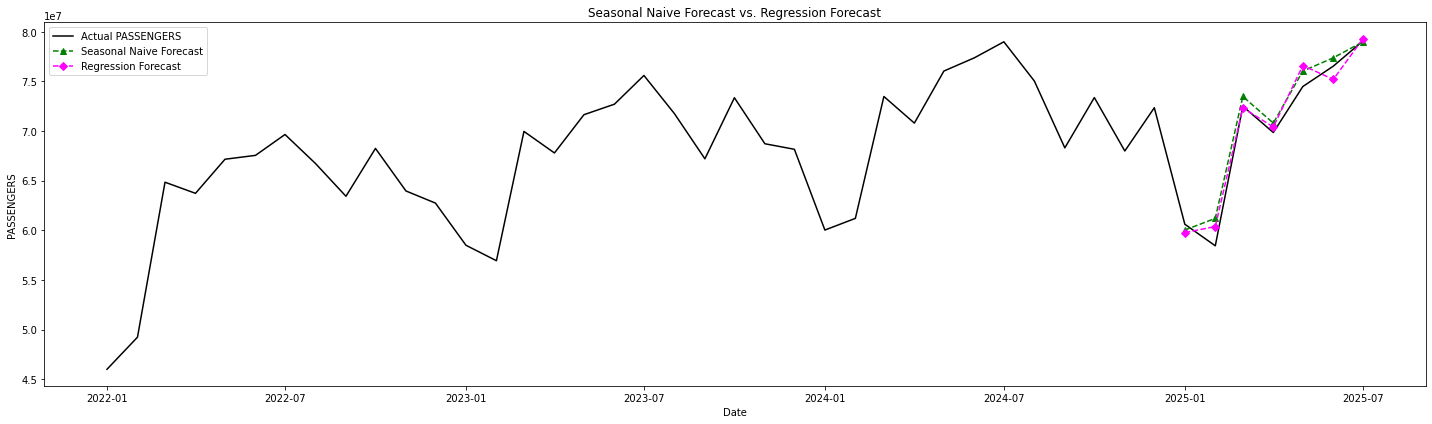

In [47]:
plt.figure(figsize=(20,6))
plt.plot(df_final.index, df_final['PASSENGERS'], label='Actual PASSENGERS', color='black')
plt.plot(test.index, test['seasonal_naive'], label='Seasonal Naive Forecast', linestyle='--', marker='^', color='green')
plt.plot(test.index, y_reg_pred, label='Regression Forecast', linestyle='--', marker='D', color='magenta')

plt.xlabel('Date')
plt.ylabel('PASSENGERS')
plt.title('Seasonal Naive Forecast vs. Regression Forecast')
plt.legend()
plt.tight_layout()
plt.show()

- The **Regression model** adds little marginal forecasting power over the simple seasonal naive approach, likely because the key seasonal patterns and level shifts are already well-captured by repeating last year’s values.

### 3.4 Random Forest Model

In [48]:
from sklearn.ensemble import RandomForestRegressor

# 7. Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_rf_pred = rf.predict(X_test)

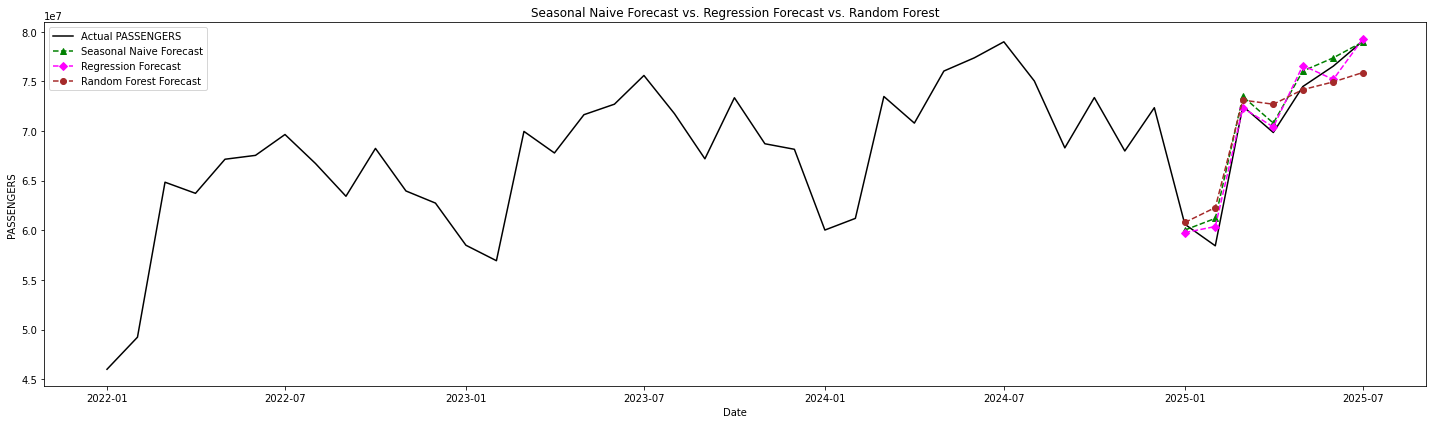

In [49]:
plt.figure(figsize=(20,6))
plt.plot(df_final.index, df_final['PASSENGERS'], label='Actual PASSENGERS', color='black')
plt.plot(test.index, test['seasonal_naive'], label='Seasonal Naive Forecast', linestyle='--', marker='^', color='green')
plt.plot(test.index, y_reg_pred, label='Regression Forecast', linestyle='--', marker='D', color='magenta')
plt.plot(test.index, y_rf_pred, label='Random Forest Forecast', linestyle='--', marker='o', color='brown')

plt.xlabel('Date')
plt.ylabel('PASSENGERS')
plt.title('Seasonal Naive Forecast vs. Regression Forecast vs. Random Forest')
plt.legend()
plt.tight_layout()
plt.show()

- **Random Forest** Forecast (brown line with circles) also tracks the actuals well, except for slight underestimations or overestimations during sharper swings.
- **Feature-driven ML models (Random Forest, Regression)** demonstrate very similar performance to Seasonal Naive, implying that most of the predictive signal is explained by seasonality.

## 3.5 Performance Evaluation

Calculating Mean Absolute Error (**MAE**), Root Mean Squared Error (**RMSE**), Mean Absolute Percentage Error (**MAPE**) and Mean Absolute Scaled Error (**MASE**)

In [50]:
mae_naive = mean_absolute_error(test['PASSENGERS'], test['naive_forecast'])
rmse_naive = np.sqrt(np.mean((test['PASSENGERS'] - test['naive_forecast'])**2))
mape_naive = np.mean(np.abs((test['PASSENGERS'] - test['naive_forecast']) / test['PASSENGERS'])) * 100
mase_naive = mae_naive / mae_naive

mae_movavg = mean_absolute_error(test['PASSENGERS'], test['movavg_forecast'])
rmse_movavg = np.sqrt(np.mean((test['PASSENGERS'] - test['movavg_forecast'])**2))
mape_movavg = np.mean(np.abs((test['PASSENGERS'] - test['movavg_forecast']) / test['PASSENGERS'])) * 100
mase_movavg = mae_movavg / mae_naive

mae_seasonal = mean_absolute_error(test['PASSENGERS'], test['seasonal_naive'])
rmse_seasonal = np.sqrt(np.mean((test['PASSENGERS'] - test['seasonal_naive'])**2))
mape_seasonal = np.mean(np.abs((test['PASSENGERS'] - test['seasonal_naive']) / test['PASSENGERS'])) * 100
mase_seasonal = mae_seasonal / mae_naive

mae_arima = mean_absolute_error(test['PASSENGERS'], arima_forecast)
rmse_arima = np.sqrt(np.mean((test['PASSENGERS'] - arima_forecast)**2))
mape_arima = np.mean(np.abs((test['PASSENGERS'] - arima_forecast) / test['PASSENGERS'])) * 100
mase_arima = mae_arima / mae_naive

mae_sarima = mean_absolute_error(test['PASSENGERS'], sarima_forecast)
rmse_sarima = np.sqrt(np.mean((test['PASSENGERS'] - sarima_forecast)**2))
mape_sarima = np.mean(np.abs((test['PASSENGERS'] - sarima_forecast) / test['PASSENGERS'])) * 100
mase_sarima = mae_sarima / mae_naive

mae_reg = mean_absolute_error(y_test, y_reg_pred)
rmse_reg = np.sqrt(np.mean((y_test - y_reg_pred)**2))
mape_reg = np.mean(np.abs((y_test - y_reg_pred) / y_test)) * 100
mase_reg = mae_reg / mae_naive

mae_rf = mean_absolute_error(y_test, y_rf_pred)
rmse_rf = np.sqrt(np.mean((y_test - y_rf_pred)**2))
mape_rf = np.mean(np.abs((y_test - y_rf_pred) / y_test)) * 100
mase_rf = mae_rf / mae_naive

In [51]:
data = {
    'Model': ['Naive','Moving Avg','Seasonal Naive','ARIMA','SARIMA','Multivariate Regression','Random Forest'],
    'MAE': [mae_naive, mae_movavg, mae_seasonal, mae_arima, mae_sarima, mae_reg, mae_rf],
    'RMSE': [rmse_naive, rmse_movavg, rmse_seasonal, rmse_arima, rmse_sarima, rmse_reg, rmse_rf],
    'MAPE': [mape_naive, mape_movavg, mape_seasonal, mape_arima, mape_sarima, mape_reg, mape_rf],
    'MASE': [mase_naive, mase_movavg, mase_seasonal, mase_arima, mase_sarima, mase_reg, mase_rf]
}

df_perf = pd.DataFrame(data)

df_perf['MAE'] = df_perf['MAE'].astype(int)
df_perf['RMSE'] = df_perf['RMSE'].astype(int)
df_perf['MAPE'] = df_perf['MAPE'].round(2)
df_perf['MASE'] = df_perf['MASE'].round(2)

df_perf = df_perf.sort_values(by='MAE', ascending=True).reset_index(drop=True)

df_perf.head(10)

,Model,MAE,RMSE,MAPE,MASE
0,Multivariate Regression,1028693,1262582,1.52,0.17
1,Seasonal Naive,1108190,1362536,1.67,0.19
2,Random Forest,1795883,2270342,2.62,0.30
3,SARIMA,5498174,5600459,7.96,0.93
4,Naive,5904493,7603876,9.11,1.00
5,ARIMA,5998446,7479470,9.18,1.02
6,Moving Avg,6061874,7370426,9.19,1.03


Regression and Seasonal Naive methods deliver leading accuracy, making them ideal for forecasting as demand follows strong seasonal cycles and trends.

SARIMA, ARIMA, Naive, and Moving Average models perform considerably low, with SARIMA showing the greatest deviation from actuals despite being a more sophisticated statistical model.

Random Forest provides moderate accuracy; however, for this dataset, additional complexity does not outperform the simple seasonal repetition.

# 4. Conclusion

- The trend analysis using decomposition of monthly PASSENGERS highlighted a clear upward trajectory with strong annual seasonality and residuals evenly scattered, indicating the data’s suitability for time series modeling with cyclical patterns.
- Stationarity testing via the Augmented Dickey-Fuller (ADF) test confirmed non-stationarity, while the autocorrelation function (ACF) displayed strong autocorrelations at lag 1 and lag 12, underscoring high temporal persistence and annual seasonality in passenger volumes.
- The EDA of categorical variables showed that most passenger traffic is concentrated within DISTANCEGROUP categories “1” and “2,” and among major airline brands, key origin-destination city pairs, and populous state combinations.
- Ultimately, forecasting models like regression and seasonal naive, driven primarily by explicit calendar and lag features such as month and lag12, tracked actual monthly passenger volumes with nearly identical accuracy, revealing that simple cyclical and calendar effects dominate the underlying demand dynamics of US airline traffic, and that adding model complexity and elaborate features yield only marginal improvements over these parsimonious approaches.

# 5. Output Datasets for Visualization in Tableau

### 5.1 EDA dataset

In [52]:
col_eda = ['CARRIER_NAME','DISTANCE_GROUP','ORIGIN_STATE_NM','ORIGIN_CITY_NAME','DEST_CITY_NAME','ORIGIN_AIRPORT_ID','DISTANCE','YEAR','MONTH']

df_eda = df.groupby(col_eda, as_index=False)['PASSENGERS'].sum()

df_eda.head()

,CARRIER_NAME,DISTANCE_GROUP,ORIGIN_STATE_NM,ORIGIN_CITY_NAME,DEST_CITY_NAME,ORIGIN_AIRPORT_ID,DISTANCE,YEAR,MONTH,PASSENGERS
0,40-Mile Air,1,Alaska,"Anchorage, AK","Fairbanks, AK",10299,261.0,2023,10,3.0
1,40-Mile Air,1,Alaska,"Anchorage, AK","Tok, AK",10299,272.0,2022,2,1.0
2,40-Mile Air,1,Alaska,"Anchorage, AK","Tok, AK",10299,272.0,2022,3,2.0
3,40-Mile Air,1,Alaska,"Anchorage, AK","Tok, AK",10299,272.0,2022,5,2.0
4,40-Mile Air,1,Alaska,"Anchorage, AK","Tok, AK",10299,272.0,2022,6,4.0


In [53]:
df_eda.to_csv(T100_DIR / 'EDA_data.csv', index=False)

### 5.2 Actual vs Forecast dataset

In [54]:
# Create forecast DataFrame from test and other predictions indexed by forecast dates
df_forecasts = pd.DataFrame(index=test.index)

# Extract forecasts from test DataFrame (same index as forecast_dates)
df_forecasts['Naive'] = test['naive_forecast']
df_forecasts['Moving Avg'] = test['movavg_forecast']
df_forecasts['Seasonal Naive'] = test['seasonal_naive']

# Other forecasts as arrays/series aligned with forecast_dates
df_forecasts['ARIMA'] = arima_forecast
df_forecasts['SARIMA'] = sarima_forecast
df_forecasts['Multivariate Regression'] = y_reg_pred
df_forecasts['Random Forest'] = y_rf_pred

# Combine Actuals & Forecasts
df_combined = df_final[['PASSENGERS']].rename(columns={'PASSENGERS': 'Actuals'}).join(df_forecasts, how='left')

df_combined.reset_index(inplace=True)  # Make date a column if preferred
df_combined.tail(13)

,DATE,Actuals,Naive,Moving Avg,Seasonal Naive,ARIMA,SARIMA,Multivariate Regression,Random Forest
30,2024-07-01,78990228.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31,2024-08-01,75039612.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
32,2024-09-01,68306882.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
33,2024-10-01,73372639.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
34,2024-11-01,67991822.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35,2024-12-01,72350347.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,2025-01-01,60613852.0,72350347.0,7.124868e+07,60026644.0,7.155150e+07,6.442522e+07,5.976702e+07,60790289.73
37,2025-02-01,58438666.0,72350347.0,7.124868e+07,61202946.0,7.208353e+07,6.583484e+07,6.038108e+07,62294101.60
38,2025-03-01,72498050.0,72350347.0,7.124868e+07,73481522.0,7.172920e+07,7.806702e+07,7.231914e+07,73117189.39
39,2025-04-01,69851898.0,72350347.0,7.124868e+07,70799807.0,7.196518e+07,7.535089e+07,7.041358e+07,72702713.83


In [55]:
# Change table from wide to long format

df_act_fcst = df_combined.melt(
    id_vars=['DATE'],                # columns to keep as-is
    var_name='Model',                # new column name for variable names
    value_name='PASSENGERS'          # new column name for values
)

df_act_fcst.head(5)

,DATE,Model,PASSENGERS
0,2022-01-01,Actuals,46000115.0
1,2022-02-01,Actuals,49233555.0
2,2022-03-01,Actuals,64845793.0
3,2022-04-01,Actuals,63725658.0
4,2022-05-01,Actuals,67160494.0


In [56]:
df_act_fcst.to_csv(T100_DIR / 'Act_Fcst_data.csv', index=False)

### 5.3 Model Performance dataset

In [57]:
df_perf.to_csv(T100_DIR / 'Model_perf.csv', index=False)